# 05_Morphing_of_TAS2R14_into_TAS2R43

In [1]:
import pandas as pd
import numpy as np
import os
import yaml

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions
from receptor_region import classify_hTAS2R_residue_region
from BW_numbers import TAS2Rs_BW_numbers
from receptor_transformation import TMSequenceTransformer
from other import read_json

import seaborn as sns
palette = sns.color_palette('Set1')

In [2]:
box_design = dict(
    boxstyle='round,pad=0.1', 
    facecolor='lightgrey', 
    edgecolor='grey', 
    alpha=1.0
)

### TMs morphing

In [3]:
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_BW_numbers = '../data/hTAS2Rs_BW_numbers.xlsx'
TM_sequence_transformer = TMSequenceTransformer(path_to_msa, path_to_BW_numbers)
BW_numbers = TAS2Rs_BW_numbers(path_to_BW_numbers)

In [4]:
source_receptor = 'TAS2R14'
target_receptor = 'TAS2R43'
TM_numbers = [3, 7]
methods = ['direct_order', 'reverse_order']

transformation_paths = {}

for TM_number in TM_numbers:
    for method in methods:
        transformation_path_name = f'morphing_of_{source_receptor}_into_{target_receptor}_TM{TM_number}_{method}'
        transformation_path = TM_sequence_transformer.TM_sequence_transform(f'h{source_receptor}', f'h{target_receptor}', TM_number, method)
        transformation_paths[transformation_path_name] = transformation_path

Number of actions required to transform hTAS2R14's TM3 into hTAS2R43's TM3: 15
Number of actions required to transform hTAS2R14's TM3 into hTAS2R43's TM3: 15
Number of actions required to transform hTAS2R14's TM7 into hTAS2R43's TM7: 18
Number of actions required to transform hTAS2R14's TM7 into hTAS2R43's TM7: 18


### Prepare configs for Boltz-2

In [5]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
aristolochic_acid_smiles = pd.read_excel(path_to_meta_file, sheet_name='ligands', index_col='ligand').loc['aristolochic acid']['smiles']

In [6]:
directory = 'Morphing_of_TAS2R14_and_TAS2R43'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.abspath(os.path.join('../configs/', directory))
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [7]:
for path_name, transformation_path in transformation_paths.items():

    path_to_directory = os.path.join(path_to_config_directory, path_name)
    if not os.path.exists(path_to_directory):
        os.makedirs(path_to_directory)

    for _, row in transformation_path.iterrows():

        step = row['step']
        
        # create config
        config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': row['transformed sequence']}}, 
                                        {'ligand': {'id': 'L', 'smiles': aristolochic_acid_smiles}}],
                          'properties': [{'affinity': {'binder': 'L'}}]}
        # save config
        config_name = f"step_{step}.yaml"
        path_to_config = os.path.join(path_to_directory, config_name)
        with open(str(path_to_config), 'w') as out:
            yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [8]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 10 --output_format pdb --use_msa_server

### Load co-folding results

In [9]:
all_cofolding_results = []
path_to_directory = '../predictions/Morphing_of_TAS2R14_and_TAS2R43/'
cofolding_directories = [file for file in os.listdir(path_to_directory) if os.path.isdir(os.path.join(path_to_directory, file))]
for cofolding_directory in cofolding_directories:

    morphing_path = transformation_paths[cofolding_directory]
    source_receptor, _, target_receptor, TM, order, _ = cofolding_directory.lstrip('morphing_of_').split('_')

    cofolding_results = []
    path_to_cofolding_directory = os.path.join(path_to_directory, cofolding_directory)
    prediction_directories = os.listdir(path_to_cofolding_directory)
    for prediction_directory in prediction_directories:
    
        step = int(prediction_directory.lstrip('step_'))
        path_to_prediction_directory = os.path.join(path_to_cofolding_directory, prediction_directory)

        affinity_file = f'affinity_{prediction_directory}.json'
        path_to_affinity_file = os.path.join(path_to_prediction_directory, affinity_file)
        affinity_data = read_json(path_to_affinity_file)
    
        pdb_files = [file for file in os.listdir(path_to_prediction_directory) if file.endswith('.pdb')]
        for pdb_file in sorted(pdb_files):
            path_to_file = os.path.join(path_to_prediction_directory, pdb_file)
            interactions = get_ligands_interactions(path_to_file)
            interactions['receptor region'] = interactions['Residue Number'].apply(lambda residue_number: classify_hTAS2R_residue_region(residue_number, source_receptor))

            confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
            path_to_confidence_file = os.path.join(path_to_prediction_directory, confidence_file)
            confidence_data = read_json(path_to_confidence_file)
            
            cofolding_results.append([cofolding_directory, source_receptor, target_receptor, TM, order, step, interactions, affinity_data, confidence_data])

    cofolding_results_df = pd.DataFrame(cofolding_results, columns=['morphing path', 'source receptor', 'target receptor', 'TM', 'order', 'step', 'interactions', 'affinity data', 'confidence data'])
    cofolding_results_df.sort_values(by='step', inplace=True, ignore_index=True)
    cofolding_results_df = cofolding_results_df.merge(morphing_path, on='step')
    all_cofolding_results.append(cofolding_results_df)
    
all_cofolding_results_df = pd.concat(all_cofolding_results, ignore_index=True)
all_cofolding_results_df['binding pocket'] = all_cofolding_results_df['interactions'].apply(lambda interactions: interactions['receptor region'].value_counts().idxmax())

In [10]:
all_cofolding_results_df['iptm'] = all_cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])
all_cofolding_results_df['affinity predicted value'] = all_cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])

In [11]:
morphing_results = []
for _, morphing_path_df in all_cofolding_results_df.groupby(by='morphing path'):
    for _, sub_df in morphing_path_df.groupby(by='step'):
        binding_site_distr = sub_df['binding pocket'].value_counts().to_dict()
        sub_df['ecbs_percent'] = binding_site_distr.setdefault('extracellular', 0) / len(sub_df) * 100
        sub_df['icbs_percent'] = binding_site_distr.setdefault('intracellular', 0) / len(sub_df) * 100
        sub_df['mean iptm'] = sub_df['iptm'].mean().round(2)
        sub_df.drop_duplicates(subset='step', inplace=True)
        morphing_results.append(sub_df)
morphing_results = pd.concat(morphing_results, ignore_index=True)

### hTAS2R14 with hTAS2R43's TM3

In [12]:
TM = 'TM3'

### direct order

<Axes: title={'center': 'TM3 direct order'}, xlabel='15 steps', ylabel='Extracellular binding, %'>

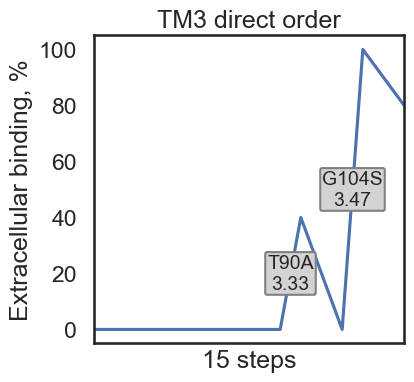

In [13]:
order = 'direct'
distr = morphing_results[(morphing_results['TM'] == TM) & (morphing_results['order'] == order)].reset_index(drop=True)

sns.set(rc={'figure.figsize':(4, 4)}, style='white', context='talk')
chart = sns.lineplot(distr, x='step', y='ecbs_percent')
max_step = distr['step'].max()
chart.set(xlim=(0, max_step), xticks=[], xlabel=f'{max_step} steps', ylabel='Extracellular binding, %', title=f"{TM} {order} order")
mutation = 'T90A'
source_receptor_residue = mutation[:-1]
number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor)
chart.text(x=10-0.5, y=20, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
mutation = 'G104S'
source_receptor_residue = mutation[:-1]
number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor)
chart.text(x=13-0.5, y=50, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
chart.figure.savefig(f'../figures/main/Figure 2F TAS2R14 into TAS2R43 morphing {TM} {order} order.png', dpi=300, bbox_inches='tight')
chart

In [14]:
distr[['transformation', 'mean iptm', 'affinity predicted value']]

,transformation,mean iptm,affinity predicted value
0,- -> -,0.88,0.737172
1,T78 -> S77,0.88,0.824248
2,E79 -> V78,0.88,0.794698
3,K80 -> E79,0.88,0.829749
4,M81 -> V80,0.89,0.870032
5,F82 -> R81,0.89,1.055236
6,R83 -> T82,0.88,0.921382
7,M84 -> T83,0.88,0.762396
8,L85 -> A84,0.87,0.746440
9,T86 -> Y85,0.89,0.792531


### reverse order

<Axes: title={'center': 'TM3 reverse order'}, xlabel='15 steps', ylabel='Extracellular binding, %'>

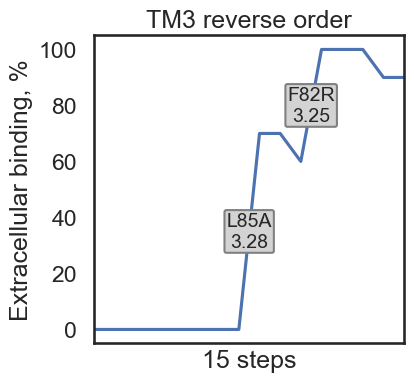

In [15]:
order = 'reverse'
distr = morphing_results[(morphing_results['TM'] == TM) & (morphing_results['order'] == order)].reset_index(drop=True)

sns.set(rc={'figure.figsize':(4, 4)}, style='white', context='talk')
chart = sns.lineplot(distr, x='step', y='ecbs_percent')
max_step = distr['step'].max()
chart.set(xlim=(0, max_step), xticks=[], xlabel=f'{max_step} steps', ylabel='Extracellular binding, %', title=f"{TM} {order} order")
mutation = 'L85A'
source_receptor_residue = mutation[:-1]
number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor.lstrip('h'))
chart.text(x=8-0.5, y=35, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
mutation = 'F82R'
source_receptor_residue = mutation[:-1]
number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor.lstrip('h'))
chart.text(x=11-0.5, y=80, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
chart.figure.savefig(f'../figures/main/Figure 2F TAS2R14 into TAS2R43 morphing {TM} {order} order.png', dpi=300, bbox_inches='tight')
chart

In [16]:
distr[['transformation', 'mean iptm', 'affinity predicted value']]

,transformation,mean iptm,affinity predicted value
0,- -> -,0.87,0.886295
1,F108 -> L107,0.88,0.696101
2,T105 -> I104,0.86,0.905488
3,G104 -> S103,0.84,0.921416
4,G102 -> T101,0.84,0.920310
5,V97 -> N96,0.82,0.921041
6,T90 -> A89,0.85,1.015043
7,T86 -> Y85,0.81,0.848784
8,L85 -> A84,0.76,1.006655
9,M84 -> T83,0.74,0.906631


### hTAS2R14 with hTAS2R43's TM7

In [17]:
TM = 'TM7'

### direct order¶

<Axes: title={'center': 'TM7 direct order'}, xlabel='18 steps', ylabel='Extracellular binding, %'>

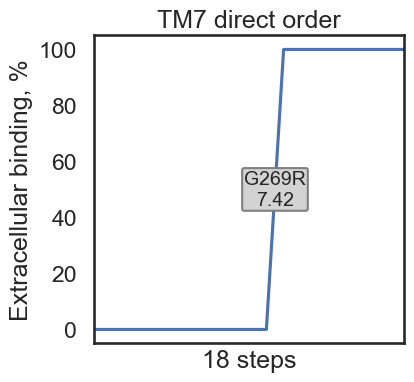

In [18]:
order = 'direct'
distr = morphing_results[(morphing_results['TM'] == TM) & (morphing_results['order'] == order)].reset_index(drop=True)

sns.set(rc={'figure.figsize':(4, 4)}, style='white', context='talk')
chart = sns.lineplot(distr, x='step', y='ecbs_percent')
max_step = distr['step'].max()
chart.set(xlim=(0, max_step), xticks=[], xlabel=f'{max_step} steps', ylabel='Extracellular binding, %', title=f"{TM} {order} order")
mutation = 'G269R'
source_receptor_residue = mutation[:-1]
# number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor.lstrip('h'))
number = '7.42'
chart.text(x=11-0.5, y=50, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
chart.figure.savefig(f'../figures/main/Figure 2F TAS2R14 into TAS2R43 morphing {TM} {order} order.png', dpi=300, bbox_inches='tight')
chart

In [19]:
distr[['transformation', 'mean iptm', 'affinity predicted value']]

,transformation,mean iptm,affinity predicted value
0,- -> -,0.87,0.689179
1,- -> K258,0.88,0.812016
2,N260 -> P259,0.88,0.863481
3,L261 -> V260,0.88,0.814038
4,I262 -> F261,0.89,0.976587
5,I263 -> M262,0.89,0.935099
6,L264 -> F263,0.89,0.729913
7,S265 -> C264,0.87,0.767623
8,Q266 -> K265,0.81,0.668536
9,V267 -> A266,0.87,0.862421


### reverse order¶

<Axes: title={'center': 'TM7 reverse order'}, xlabel='18 steps', ylabel='Extracellular binding, %'>

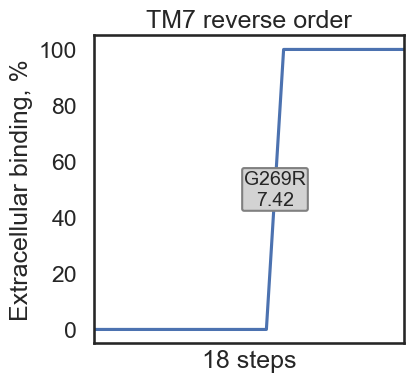

In [20]:
order = 'reverse'
distr = morphing_results[(morphing_results['TM'] == TM) & (morphing_results['order'] == order)].reset_index(drop=True)

sns.set(rc={'figure.figsize':(4, 4)}, style='white', context='talk')
chart = sns.lineplot(distr, x='step', y='ecbs_percent')
max_step = distr['step'].max()
chart.set(xlim=(0, max_step), xticks=[], xlabel=f'{max_step} steps', ylabel='Extracellular binding, %', title=f"{TM} {order} order")
mutation = 'G269R'
source_receptor_residue = mutation[:-1]
# number = BW_numbers.get_BW_number(residue=source_receptor_residue, receptor=source_receptor.lstrip('h'))
number = '7.42'
chart.text(x=11-0.5, y=50, s=f'{mutation}\n{number}', size=14, ha='center', va='center', bbox=box_design)
chart.figure.savefig(f'../figures/main/Figure 2F TAS2R14 into TAS2R43 morphing {TM} {order} order.png', dpi=300, bbox_inches='tight')
chart

In [21]:
distr[['transformation', 'mean iptm', 'affinity predicted value']]

,transformation,mean iptm,affinity predicted value
0,- -> -,0.88,0.779729
1,L282 -> W281,0.86,0.766635
2,V279 -> I278,0.86,0.992038
3,C278 -> F277,0.87,0.674841
4,S277 -> P276,0.88,0.793275
5,C275 -> I274,0.89,0.893328
6,A271 -> S270,0.89,0.743582
7,M270 -> F269,0.88,0.818273
8,G269 -> R268,0.84,0.791462
9,M268 -> I267,0.85,0.781914
